# Contextual Word and Sentence Similarity Using BERT

## 1. Introduction

This project applies a pre-trained BERT model using the Hugging Face Transformers library to explore contextual embeddings and sentence similarity. The project involves extracting token-level embeddings, demonstrating polysemy, generating sentence representations, and calculating cosine similarity between sentence pairs.

A similarity threshold of 0.7 is used to classify sentence pairs as either similar or not similar. The resulting predictions are compared against manually assigned ground-truth labels to evaluate the accuracy of the approach.

## Section 2: Importing libraries

The libraries required for BERT implementation, numerical operations, data manipulation, similarity computation, evaluation, and visualization are imported below.

In [1]:
# Import libraries for NLP and deep learning
import torch
import numpy as np
import pandas as pd

# Import BERT components
from transformers import AutoTokenizer, AutoModel

# Import similarity and evaluation metrics
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import accuracy_score

# Import visualization library
import matplotlib.pyplot as plt

# Display library versions
print("PyTorch version:", torch.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

print("\nAll libraries imported successfully.")

PyTorch version: 2.15.0+cpu
NumPy version: 2.5.5
Pandas version: 3.1.1

All libraries imported successfully.


## Section 3: Creating sentence pairs

We will use the five sentence pairs provided in the assignment and add five additional pairs. Each pair will have a manually assigned ground-truth label:
- 1 – The sentences have similar meanings.
- 0 – The sentences have different meanings.
These labels will later be compared with BERT's predictions to calculate classification accuracy.

In [2]:
# Define the 10 sentence pairs and their ground-truth labels

sentence_pairs = [
    # Original sentence pairs
    ("How do I learn Python?", "What is the best way to study Python?"),
    ("What is AI?", "How to cook pasta?"),
    ("How do I bake a chocolate cake?", "Give me a chocolate cake recipe."),
    ("How can I improve my coding skills?", "Tips for becoming better at programming."),
    ("Where can I buy cheap laptops?", "Best sites to find affordable computers."),

    # Additional sentence pairs
    ("What is machine learning?", "Explain the concept of machine learning."),
    ("How can I lose weight?", "What are the benefits of regular exercise?"),
    ("What is the capital of Kenya?", "Nairobi is the capital city of Kenya."),
    ("How do I create a website?", "What are the steps to build a website?"),
    ("What causes climate change?", "How can I prepare for a job interview?")
]

# Assign manually determined ground-truth labels
true_labels = [1, 0, 1, 1, 1, 1, 0, 1, 1, 0]

# Create a DataFrame
df = pd.DataFrame({
    "Sentence 1": [pair[0] for pair in sentence_pairs],
    "Sentence 2": [pair[1] for pair in sentence_pairs],
    "Ground Truth": true_labels
})

# Display the sentence pairs
display(df)

,Sentence 1,Sentence 2,Ground Truth
0,How do I learn Python?,What is the best way to study Python?,1
1,What is AI?,How to cook pasta?,0
2,How do I bake a chocolate cake?,Give me a chocolate cake recipe.,1
3,How can I improve my coding skills?,Tips for becoming better at programming.,1
4,Where can I buy cheap laptops?,Best sites to find affordable computers.,1
5,What is machine learning?,Explain the concept of machine learning.,1
6,How can I lose weight?,What are the benefits of regular exercise?,0
7,What is the capital of Kenya?,Nairobi is the capital city of Kenya.,1
8,How do I create a website?,What are the steps to build a website?,1
9,What causes climate change?,How can I prepare for a job interview?,0


Output interpretation

The output displays a table containing ten sentence pairs and their manually assigned labels.

Pairs with label 1 represent semantically similar sentences, while pairs with label 0 represent sentences with different meanings.

Important: These are our reference labels, not BERT predictions. We will use them later to evaluate the classification results.

## Section 4: Loading the pre-trained BERT model

We will use bert-base-uncased from Hugging Face. The model consists of 12 transformer encoder layers and produces contextual representations of tokens.

We will load both the tokenizer and the pre-trained model

In [3]:
# Load the pre-trained BERT tokenizer and model

model_name = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)

# Set model to evaluation mode
model.eval()

# Select the available computing device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Move model to the selected device
model.to(device)

print("BERT model loaded successfully!")
print("Model:", model_name)
print("Device:", device)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

c:\Users\Admin\Documents\bert-contextual-embeddings-simmilarity\bert-contextual-embeddings-similarity\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Admin\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

c:\Users\Admin\Documents\bert-contextual-embeddings-simmilarity\bert-contextual-embeddings-similarity\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Admin\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT model loaded successfully!
Model: bert-base-uncased
Device: cpu


## Section 5: Tokenizing a sentence

BERT cannot process raw text directly. The tokenizer converts a sentence into numerical token IDs that the model can understand. It also adds special tokens such as [CLS] and [SEP].

In [4]:
sentence = "The bank is located near the river."

inputs = tokenizer(sentence, return_tensors="pt")

print("Original sentence:")
print(sentence)

print("\nTokenized words:")
print(tokenizer.convert_ids_to_tokens(inputs["input_ids"][0]))

print("\nToken IDs:")
print(inputs["input_ids"][0])

print("\nAttention mask:")
print(inputs["attention_mask"][0])

Original sentence:
The bank is located near the river.

Tokenized words:
['[CLS]', 'the', 'bank', 'is', 'located', 'near', 'the', 'river', '.', '[SEP]']

Token IDs:
tensor([ 101, 1996, 2924, 2003, 2284, 2379, 1996, 2314, 1012,  102])

Attention mask:
tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1])


## Section 6: Extracting contextual embeddings

BERT converts each token into a contextual embedding, which is a numerical representation influenced by the surrounding words. BERT-base produces a 768-dimensional embedding for each token.

In [5]:
inputs = {key: value.to(device) for key, value in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

token_embeddings = outputs.last_hidden_state

print("Embedding shape:", token_embeddings.shape)
print("\nEmbedding for the word 'bank':")
print(token_embeddings[0, 2, :])

Embedding shape: torch.Size([1, 10, 768])

Embedding for the word 'bank':
tensor([-1.4819e-01, -4.8720e-01, -2.5740e-01, -2.2184e-01,  8.7318e-01,
         2.8648e-01, -3.9389e-01,  4.9092e-01,  2.1730e-01, -3.8566e-01,
         5.1816e-01, -2.1133e-02, -1.3669e-01,  3.4649e-01, -1.0258e+00,
         8.9269e-02,  1.2328e-01,  1.7035e-01,  1.0187e+00,  4.1390e-02,
        -1.3097e-01,  3.1603e-01,  2.1651e-01,  1.1770e-01, -9.5857e-03,
         2.0386e-01,  3.1053e-01,  6.2062e-01,  3.0310e-01,  2.1378e-02,
         9.2768e-01,  2.1548e-01,  5.1533e-01,  2.6854e-01, -2.6909e-01,
        -3.5942e-01, -9.2079e-02, -2.8917e-02, -4.3515e-01, -8.5137e-02,
         2.9392e-01, -4.1958e-01, -3.0583e-01,  5.8535e-01, -3.6903e-01,
        -3.4126e-01, -5.9823e-01,  2.2239e-01, -1.2043e-01,  2.5805e-01,
        -2.1666e-01,  5.0390e-01, -2.7641e-01, -1.0184e-01,  3.5636e-01,
         5.7203e-01, -5.8364e-01,  1.7992e-02,  2.7110e-01, -2.4092e-01,
         6.0199e-01,  7.7201e-03,  3.9189e-01, -9.

## Section 7: Demonstrating polysemy

Polysemy occurs when the same word has different meanings depending on its context. We will compare the word bank in two sentences:
1. "She deposited money at the bank." — financial institution.
2. "They sat on the bank of the river." — land beside a river.
BERT should generate different contextual embeddings for the word because the surrounding words provide different meanings.

In [6]:
sentence1 = "She deposited money at the bank."
sentence2 = "They sat on the bank of the river."

def get_word_embedding(sentence, target_word):
    inputs = tokenizer(sentence, return_tensors="pt")
    inputs = {key: value.to(device) for key, value in inputs.items()}

    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

    with torch.no_grad():
        outputs = model(**inputs)

    word_index = tokens.index(target_word)
    embedding = outputs.last_hidden_state[0, word_index, :]

    return embedding

bank_embedding1 = get_word_embedding(sentence1, "bank")
bank_embedding2 = get_word_embedding(sentence2, "bank")

print("Sentence 1:", sentence1)
print("Sentence 2:", sentence2)
print("\nEmbedding shape:", bank_embedding1.shape)

Sentence 1: She deposited money at the bank.
Sentence 2: They sat on the bank of the river.

Embedding shape: torch.Size([768])


## Section 8: Calculating cosine similarity

Cosine similarity measures how similar two vectors are by calculating the cosine of the angle between them. A value closer to 1 indicates greater similarity, while a value closer to 0 indicates less similarity.

We will use it to compare the two contextual representations of bank.

In [7]:
similarity = cosine_similarity(
    bank_embedding1.cpu().numpy().reshape(1, -1),
    bank_embedding2.cpu().numpy().reshape(1, -1)
)[0][0]

print("Cosine Similarity:", similarity)

Cosine Similarity: 0.54004204


Output Interpretation

Sentence 1 uses bank to refer to a financial institution.
Sentence 2 uses bank to refer to the land beside a river.

The cosine similarity of 0.54 indicates that the two embeddings are not highly similar, despite representing the same written word.

## Section 9: Creating sentence embeddings

We will now move from token-level embeddings to sentence-level embeddings. We will use mean pooling to combine the embeddings of individual words into one representation for each sentence.

These sentence embeddings will be used to calculate similarity across all ten sentence pairs.

In [8]:
def get_sentence_embedding(sentence):
    inputs = tokenizer(
        sentence,
        return_tensors="pt",
        truncation=True,
        return_special_tokens_mask=True
    )

    special_tokens_mask = inputs.pop("special_tokens_mask").to(device)
    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)

    token_embeddings = outputs.last_hidden_state

    attention_mask = inputs["attention_mask"]
    valid_mask = attention_mask * (1 - special_tokens_mask)
    valid_mask = valid_mask.unsqueeze(-1).float()

    summed_embeddings = (token_embeddings * valid_mask).sum(dim=1)
    token_count = valid_mask.sum(dim=1)

    sentence_embedding = summed_embeddings / token_count

    return sentence_embedding.cpu().numpy()[0]


test_embedding = get_sentence_embedding("What is machine learning?")

print("Sentence embedding shape:", test_embedding.shape)

Sentence embedding shape: (768,)


This means mean pooling successfully combined the contextual token embeddings into one 768-dimensional sentence representation.

## Section 10: Calculating sentence similarity for all 10 pairs

We will generate sentence embeddings for each sentence pair and calculate their cosine similarity. We will then apply the assignment's threshold:
- Similarity greater than 0.7 → Predicted label 1 (Similar).
- Similarity of 0.7 or below → Predicted label 0 (Not similar).

In [9]:
similarity_scores = []
predicted_labels = []

for sentence1, sentence2 in sentence_pairs:
    embedding1 = get_sentence_embedding(sentence1)
    embedding2 = get_sentence_embedding(sentence2)

    score = cosine_similarity(
        embedding1.reshape(1, -1),
        embedding2.reshape(1, -1)
    )[0][0]

    prediction = 1 if score > 0.7 else 0

    similarity_scores.append(score)
    predicted_labels.append(prediction)

df["Similarity Score"] = similarity_scores
df["Predicted Label"] = predicted_labels

display(df)

,Sentence 1,Sentence 2,Ground Truth,Similarity Score,Predicted Label
0,How do I learn Python?,What is the best way to study Python?,1,0.815928,1
1,What is AI?,How to cook pasta?,0,0.571155,0
2,How do I bake a chocolate cake?,Give me a chocolate cake recipe.,1,0.820660,1
3,How can I improve my coding skills?,Tips for becoming better at programming.,1,0.666629,0
4,Where can I buy cheap laptops?,Best sites to find affordable computers.,1,0.732216,1
5,What is machine learning?,Explain the concept of machine learning.,1,0.775912,1
6,How can I lose weight?,What are the benefits of regular exercise?,0,0.686988,0
7,What is the capital of Kenya?,Nairobi is the capital city of Kenya.,1,0.661763,0
8,How do I create a website?,What are the steps to build a website?,1,0.836715,1
9,What causes climate change?,How can I prepare for a job interview?,0,0.603633,0


There are two interesting cases worth highlighting:

- Pair 4 (coding skills): Ground truth is 1, but the model predicts 0 because its score (0.6666) is below the 0.7 threshold.
- Pair 8 (capital of Kenya): Ground truth is 1, but the model predicts 0 despite the sentences expressing the same fact. Its score is 0.6618.
These are false negatives: semantically similar sentences that the model classified as dissimilar.

## Section 11: Evaluating model accuracy

We will use Scikit-learn's accuracy_score to evaluate the predictions.

In [10]:
accuracy = accuracy_score(true_labels, predicted_labels)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 80.0 %


## Section 12: Visualizing sentence similarity scores

A bar chart helps us compare the similarity scores of all ten sentence pairs. The horizontal line represents the classification threshold of 0.7.

Scores above the line are classified as similar, while scores at or below it are classified as not similar.

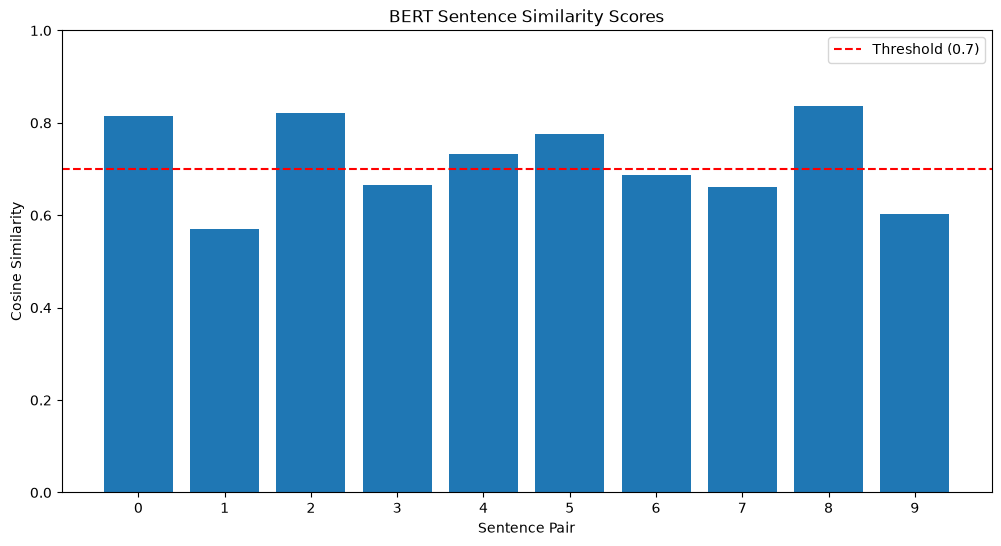

In [11]:
plt.figure(figsize=(12, 6))

plt.bar(range(len(similarity_scores)), similarity_scores)

plt.axhline(
    y=0.7,
    color="red",
    linestyle="--",
    label="Threshold (0.7)"
)

plt.xlabel("Sentence Pair")
plt.ylabel("Cosine Similarity")
plt.title("BERT Sentence Similarity Scores")
plt.xticks(range(len(similarity_scores)))
plt.legend()
plt.ylim(0, 1)

plt.show()

Interpretation of the Similarity Visualization

The bar chart illustrates the cosine similarity scores for the ten sentence pairs. Five pairs achieved scores above the 0.7 threshold and were classified as semantically similar. The remaining five pairs scored below the threshold and were classified as dissimilar. Pair 8 recorded the highest similarity score (approximately 0.84), while pair 1 recorded the lowest (approximately 0.57). The visualization demonstrates how the selected threshold influences BERT's sentence classification results.

## Section 13: Confusion matrix

A confusion matrix provides a more detailed evaluation of the model by comparing its predicted labels with the actual ground-truth labels. It identifies correct and incorrect classifications.

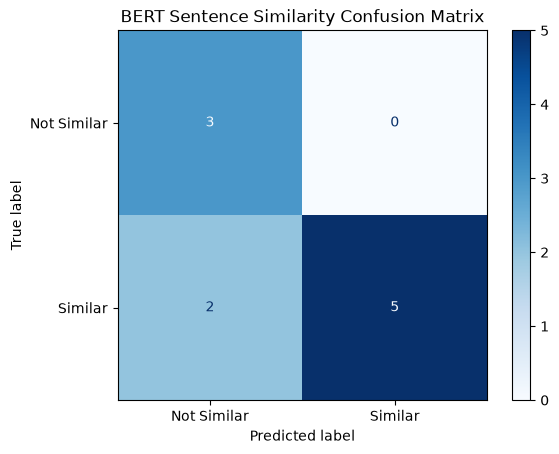

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(true_labels, predicted_labels)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Similar", "Similar"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("BERT Sentence Similarity Confusion Matrix")
plt.show()

Interpretation

The confusion matrix shows that the model correctly classified three dissimilar sentence pairs and five similar sentence pairs. It recorded no false positives but produced two false negatives, meaning that two semantically similar sentence pairs were incorrectly classified as dissimilar. Overall, the model achieved 80% accuracy.

## Section 14: Comparing BERT with traditional NLP

Traditional NLP approaches, such as Bag of Words and TF-IDF, represent text using word frequencies or statistical weights. These methods generally do not capture the contextual meaning of words.

BERT uses a transformer architecture to generate contextual embeddings. It considers surrounding words to understand meaning, allowing the same word to have different representations depending on its context.

| Feature | Traditional NLP | BERT |
|---|---|---|
| Word representation | Frequency-based or static | Contextual |
| Context understanding | Limited | Bidirectional context |
| Polysemy handling | Limited | Better contextual representation |
| Architecture | Statistical methods | Transformer |
| Semantic understanding | Limited | More advanced |

## Conclusion

This practical demonstrated how BERT can generate contextual word and sentence embeddings for semantic similarity analysis. The polysemy experiment showed that the word bank received different representations in financial and geographical contexts. The sentence similarity experiment achieved 80% accuracy using a 0.7 threshold.

The results demonstrate the usefulness of contextual embeddings in NLP while highlighting that a fixed similarity threshold may misclassify some semantically related sentences.

## Limitations and Recommendations

### Limitations

1. **Small Dataset:** The experiment used only ten sentence pairs, which may not adequately represent different types of semantic relationships.

2. **Fixed Similarity Threshold:** The 0.7 threshold may not be suitable for every sentence pair and can lead to incorrect classifications.

3. **Model Limitations:** Although BERT captures contextual meaning, it may not always identify subtle semantic relationships accurately.

4. **Mean Pooling:** Combining token embeddings through mean pooling may lose some important information about sentence structure and word relationships.

### Recommendations

1. **Increase Dataset Size:** Use a larger and more diverse dataset to improve the reliability of the evaluation.

2. **Experiment with Thresholds:** Test different similarity thresholds to identify one that produces better classification results.

3. **Explore Other Models:** Compare BERT with other pre-trained language models, such as Sentence-BERT, for sentence similarity tasks.

4. **Improve Sentence Representations:** Explore alternative pooling techniques to determine whether they produce better sentence embeddings.